# Experiment 8: K-Means Clustering with Elbow and Silhouette Methods
**Aim:** Apply K-Means clustering and find the optimal number of clusters using the Elbow method and Silhouette score.

**Dataset:** Mall Customers (`Mall_Customers.csv`): 200 customers. Features used: `Annual Income (k$)` and `Spending Score (1-100)`.

In [1]:
print("Name    : Pranav Santosh Swami")
print("Roll no : 71")

Name    : Pranav Santosh Swami
Roll no : 71


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("Mall_Customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Try k = 2 to 10, recording WCSS (for Elbow) and Silhouette score

In [5]:
k_values = range(2, 11)
wcss = []
sil_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)                       # within-cluster sum of squares
    sil_scores.append(silhouette_score(X_scaled, labels))

pd.DataFrame({"k": k_values, "WCSS": wcss, "Silhouette Score": sil_scores}).round(4)

,k,WCSS,Silhouette Score
0,2,270.7043,0.3147
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.9112,0.5263
6,8,37.7364,0.4558
7,9,32.3753,0.4553
8,10,29.0906,0.4476


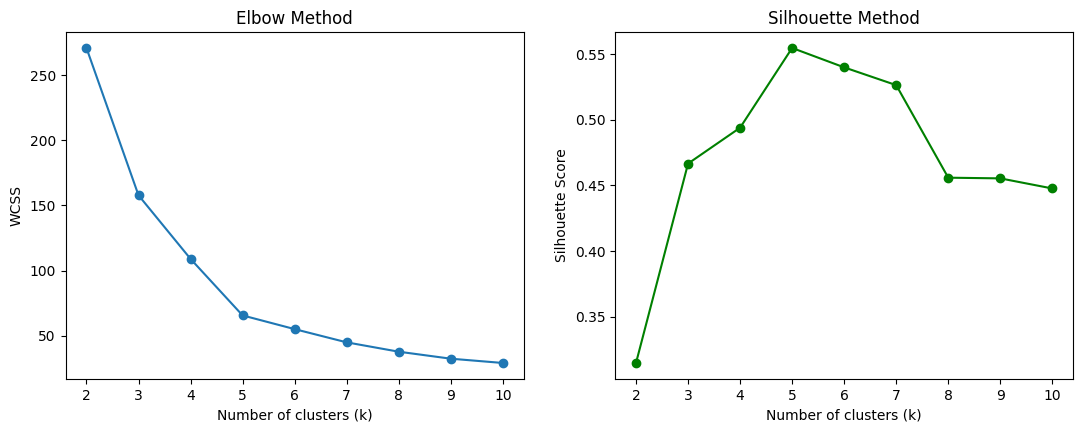

Optimal k (highest silhouette score): 5


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(k_values, wcss, marker="o")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("WCSS")
ax[0].set_title("Elbow Method")

ax[1].plot(k_values, sil_scores, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Method")
plt.show()

best_k = k_values[np.argmax(sil_scores)]
print("Optimal k (highest silhouette score):", best_k)

## Final K-Means with the optimal k

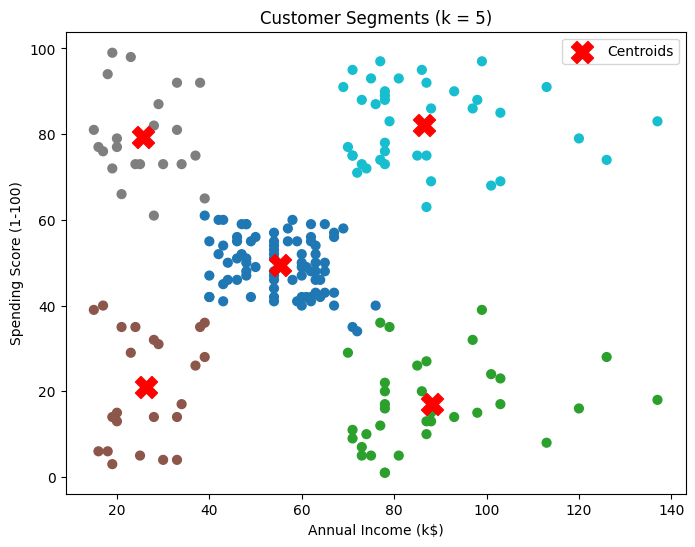

In [7]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)
centers = scaler.inverse_transform(kmeans.cluster_centers_)     # back to original units

plt.figure(figsize=(8, 6))
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], c=df["Cluster"], cmap="tab10", s=40)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=250, label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"Customer Segments (k = {best_k})")
plt.legend()
plt.show()

In [8]:
# average income and spending of each customer group
summary = df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)
summary["Customers"] = df["Cluster"].value_counts().sort_index()
summary

,Annual Income (k$),Spending Score (1-100),Customers
Cluster,,,
0,55.3,49.5,81
1,88.2,17.1,35
2,26.3,20.9,23
3,25.7,79.4,22
4,86.5,82.1,39


## Conclusion
The Elbow curve bends at **k = 5** and the Silhouette score is highest at **k = 5 (≈0.55)**, so the optimal number of clusters is 5. The 5 customer groups are: low income–low spend, low income–high spend, average income–average spend, high income–low spend, and high income–high spend (the target customers).